
# TRABAJO FINAL INTEGRADOR
## Análisis de ingresos y gastos de estudiantes universitarios

### 1. Introducción

El presente proyecto tiene como finalidad analizar los ingresos y gastos de estudiantes universitarios, identificando sus principales categorías de consumo y los posibles patrones relacionados con sus características personales y académicas.

### 2. Objetivo general

Analizar cómo administran sus ingresos los estudiantes universitarios y cuáles son sus principales categorías de gastos.

### 3. Herramientas utilizadas

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Power BI
- GitHub


In [2]:

# Cargar archivo CSV desde la computadora

from google.colab import files
import pandas as pd

# Seleccionar el archivo
uploaded = files.upload()

# Leer el archivo
nombre_archivo = next(iter(uploaded))
df = pd.read_csv(nombre_archivo)

# Confirmar que se cargó correctamente
print("¡Archivo cargado correctamente!")

# Mostrar los primeros 5 registros
display(df.head())

# Mostrar cantidad de filas y columnas
print("Dimensiones del dataset:", df.shape)


Saving datasetdos.csv to datasetdos (1).csv
¡Archivo cargado correctamente!


,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


Dimensiones del dataset: (499, 18)


In [3]:

# ==========================================
# 1. EXPLORACIÓN INICIAL DEL DATASET
# ==========================================

# Mostrar las primeras 5 filas
display(df.head())

# Mostrar las últimas 5 filas
display(df.tail())

# Cantidad de filas y columnas
print("Cantidad de filas y columnas:", df.shape)

# Nombres de las columnas
print("\nNombres de las columnas:")
print(df.columns.tolist())


,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
494,494,21,Female,Senior,Computer Science,540,931,4582,651,221,135,100,21,39,75,72,183,Mobile Payment App
495,495,25,Non-binary,Freshman,Psychology,737,995,4234,562,288,62,293,103,89,281,31,162,Mobile Payment App
496,496,22,Non-binary,Freshman,Psychology,503,57,3138,843,276,177,175,37,26,258,105,165,Cash
497,497,22,Female,Freshman,Computer Science,673,972,5357,828,279,95,298,97,21,154,34,162,Mobile Payment App
498,498,25,Female,Freshman,Psychology,681,115,5355,848,209,118,51,112,83,240,188,172,Cash


Cantidad de filas y columnas: (499, 18)

Nombres de las columnas:
['Unnamed: 0', 'age', 'gender', 'year_in_school', 'major', 'monthly_income', 'financial_aid', 'tuition', 'housing', 'food', 'transportation', 'books_supplies', 'entertainment', 'personal_care', 'technology', 'health_wellness', 'miscellaneous', 'preferred_payment_method']


In [4]:

# ==========================================
# 2. INFORMACIÓN GENERAL DEL DATASET
# ==========================================

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Unnamed: 0                499 non-null    int64 
 1   age                       499 non-null    int64 
 2   gender                    499 non-null    object
 3   year_in_school            499 non-null    object
 4   major                     499 non-null    object
 5   monthly_income            499 non-null    int64 
 6   financial_aid             499 non-null    int64 
 7   tuition                   499 non-null    int64 
 8   housing                   499 non-null    int64 
 9   food                      499 non-null    int64 
 10  transportation            499 non-null    int64 
 11  books_supplies            499 non-null    int64 
 12  entertainment             499 non-null    int64 
 13  personal_care             499 non-null    int64 
 14  technology                

In [5]:

# ==========================================
# 4. CONTROL DE CALIDAD
# ==========================================

# Valores nulos
print("Valores nulos por columna:")
print(df.isnull().sum())

# Filas duplicadas
print("\nCantidad de filas duplicadas:")
print(df.duplicated().sum())

# Cantidad total de valores nulos
print("\nTotal de valores nulos:")
print(df.isnull().sum().sum())


Valores nulos por columna:
Unnamed: 0                  0
age                         0
gender                      0
year_in_school              0
major                       0
monthly_income              0
financial_aid               0
tuition                     0
housing                     0
food                        0
transportation              0
books_supplies              0
entertainment               0
personal_care               0
technology                  0
health_wellness             0
miscellaneous               0
preferred_payment_method    0
dtype: int64

Cantidad de filas duplicadas:
0

Total de valores nulos:
0


Análisis estadístico descriptivo

In [6]:

# ==========================================
# 5. ESTADISTICAS DESCRIPTIVAS
# ==========================================

# Analizamos las variables numericas
display(df.describe())

# Calculamos el promedio de edad
print("Edad promedio de los estudiantes:",
      df["age"].mean())

# Calculamos el ingreso mensual promedio
print("Ingreso mensual promedio:",
      df["monthly_income"].mean())

# Calculamos la ayuda financiera promedio
print("Ayuda financiera promedio:",
      df["financial_aid"].mean())


,Unnamed: 0,age,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous
count,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000
mean,249.000000,21.627255,1016.749499,500.541082,4525.557114,691.084168,253.184369,127.136273,170.579158,84.238477,61.597194,178.128257,113.094188,107.164329
std,144.193157,2.328740,294.108583,293.575479,884.578668,170.334106,87.808081,44.157593,72.528067,37.490256,23.044049,70.043701,50.176847,52.133643
min,0.000000,18.000000,502.000000,0.000000,3003.000000,403.000000,100.000000,50.000000,50.000000,20.000000,20.000000,50.000000,30.000000,20.000000
25%,124.500000,20.000000,766.500000,250.500000,3788.500000,537.500000,176.000000,90.000000,109.500000,52.500000,43.000000,117.000000,67.500000,62.000000
50%,249.000000,22.000000,1004.000000,492.000000,4548.000000,695.000000,255.000000,127.000000,170.000000,85.000000,64.000000,178.000000,112.000000,109.000000
75%,373.500000,24.000000,1286.000000,762.500000,5305.500000,835.000000,331.000000,167.000000,229.000000,115.000000,81.000000,238.500000,159.000000,152.500000
max,498.000000,25.000000,1496.000000,998.000000,5998.000000,1000.000000,400.000000,200.000000,300.000000,150.000000,100.000000,299.000000,200.000000,200.000000


Edad promedio de los estudiantes: 21.627254509018037
Ingreso mensual promedio: 1016.7494989979959
Ayuda financiera promedio: 500.54108216432866


### Interpretación del análisis estadístico

A partir del análisis estadístico descriptivo, se observa que la edad promedio de los estudiantes es de aproximadamente 21,63 años. En cuanto a los ingresos, el promedio mensual registrado es de 1.016,75 unidades monetarias, mientras que la ayuda financiera presenta un promedio de 500,54 unidades monetarias.

Estos resultados permiten obtener una primera aproximación a la situación económica de los estudiantes universitarios y sirven como punto de partida para analizar cómo se distribuyen sus ingresos y gastos.

Detección de valores extremos (outliers)

In [7]:
# ==========================================
# 6. DETECCIÓN DE VALORES EXTREMOS
# ==========================================

# Seleccionamos las columnas numéricas
columnas_numericas = df.select_dtypes(include="number").columns

# Calculamos los valores mínimos y máximos
# para cada variable numérica
for columna in columnas_numericas:
    print("Variable:", columna)
    print("Mínimo:", df[columna].min())
    print("Máximo:", df[columna].max())
    print("-----------------------------")

Variable: Unnamed: 0
Mínimo: 0
Máximo: 498
-----------------------------
Variable: age
Mínimo: 18
Máximo: 25
-----------------------------
Variable: monthly_income
Mínimo: 502
Máximo: 1496
-----------------------------
Variable: financial_aid
Mínimo: 0
Máximo: 998
-----------------------------
Variable: tuition
Mínimo: 3003
Máximo: 5998
-----------------------------
Variable: housing
Mínimo: 403
Máximo: 1000
-----------------------------
Variable: food
Mínimo: 100
Máximo: 400
-----------------------------
Variable: transportation
Mínimo: 50
Máximo: 200
-----------------------------
Variable: books_supplies
Mínimo: 50
Máximo: 300
-----------------------------
Variable: entertainment
Mínimo: 20
Máximo: 150
-----------------------------
Variable: personal_care
Mínimo: 20
Máximo: 100
-----------------------------
Variable: technology
Mínimo: 50
Máximo: 299
-----------------------------
Variable: health_wellness
Mínimo: 30
Máximo: 200
-----------------------------
Variable: miscellaneous
Mí

### Interpretación de la detección de valores extremos



Los resultados mostraron que ninguna de las variables presentó valores fuera de los límites establecidos por este método.

Por lo tanto, no se detectaron posibles valores extremos mediante este procedimiento. Se conservaron todos los registros originales, sin eliminar datos.

Análisis de variables categóricas

In [9]:
# ==========================================
# 8. ANÁLISIS DE VARIABLES CATEGÓRICAS
# ==========================================

columnas_categoricas = df.select_dtypes(
    include="object"
).columns

for columna in columnas_categoricas:
    print("\nVariable:", columna)
    print(df[columna].value_counts())
    print("-----------------------------")


Variable: gender
gender
Female        183
Male          168
Non-binary    148
Name: count, dtype: int64
-----------------------------

Variable: year_in_school
year_in_school
Freshman     136
Senior       131
Sophomore    119
Junior       113
Name: count, dtype: int64
-----------------------------

Variable: major
major
Economics           109
Biology             107
Psychology           95
Computer Science     95
Engineering          93
Name: count, dtype: int64
-----------------------------

Variable: preferred_payment_method
preferred_payment_method
Mobile Payment App    180
Credit/Debit Card     169
Cash                  150
Name: count, dtype: int64
-----------------------------


Limpieza y preparación de los datos

In [10]:
# ==========================================
# 9. LIMPIEZA Y PREPARACIÓN DE LOS DATOS
# ==========================================

# Creamos una copia del dataset original
df_limpio = df.copy()

# Revisamos si la columna Unnamed: 0 es un índice
print("Primeros valores de la columna:")
print(df_limpio["Unnamed: 0"].head())

# Comprobamos si contiene números consecutivos
print(
    "¿Es un índice consecutivo?",
    df_limpio["Unnamed: 0"].reset_index(drop=True).equals(
        pd.Series(range(len(df_limpio)))
    )
)

Primeros valores de la columna:
0    0
1    1
2    2
3    3
4    4
Name: Unnamed: 0, dtype: int64
¿Es un índice consecutivo? True


In [11]:
# Eliminamos la columna que funciona como índice
df_limpio = df_limpio.drop(columns=["Unnamed: 0"])

# Comprobamos las dimensiones del dataset limpio
print("Dimensiones originales:", df.shape)
print("Dimensiones del dataset limpio:", df_limpio.shape)

# Mostramos las columnas que quedaron
print("Columnas del dataset limpio:")
print(df_limpio.columns.tolist())

# Mostramos las primeras filas
display(df_limpio.head())

Dimensiones originales: (499, 18)
Dimensiones del dataset limpio: (499, 17)
Columnas del dataset limpio:
['age', 'gender', 'year_in_school', 'major', 'monthly_income', 'financial_aid', 'tuition', 'housing', 'food', 'transportation', 'books_supplies', 'entertainment', 'personal_care', 'technology', 'health_wellness', 'miscellaneous', 'preferred_payment_method']


,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


### Resultados de la limpieza de datos

Durante el proceso de preparación se identificó que la columna `Unnamed: 0` contenía una numeración consecutiva de los registros, por lo que se determinó que funcionaba como un índice y no aportaba información relevante para el análisis.

Se creó una copia del dataset original y se eliminó dicha columna de la copia, conservando los 499 registros y las 17 variables restantes.

Además, se mantuvieron los datos originales, ya que no se detectaron valores nulos, registros duplicados ni posibles valores extremos mediante el método IQR.

Análisis exploratorio de datos (EDA)

In [12]:
# ==========================================
# 10. PREPARACIÓN PARA EL ANÁLISIS VISUAL
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo de los gráficos
sns.set_theme(style="whitegrid")

print("Herramientas para gráficos cargadas correctamente")

Herramientas para gráficos cargadas correctamente


Distribución de edades de los estudiantes

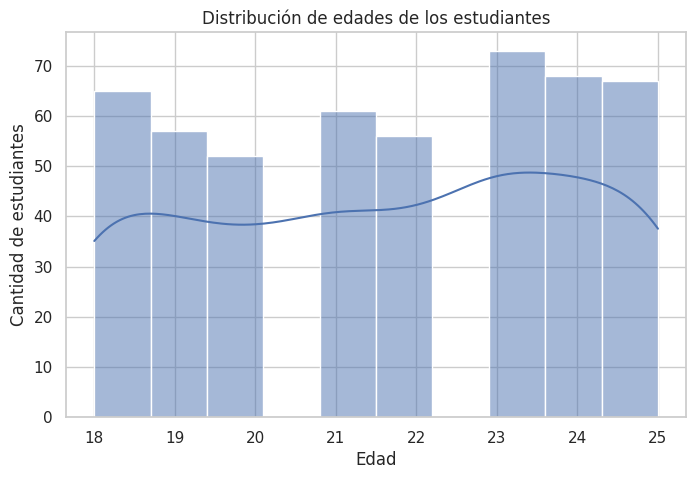

In [13]:
# Gráfico de distribución de edades

plt.figure(figsize=(8,5))

sns.histplot(
    data=df_limpio,
    x="age",
    bins=10,
    kde=True
)

plt.title("Distribución de edades de los estudiantes")
plt.xlabel("Edad")
plt.ylabel("Cantidad de estudiantes")

plt.show()

Distribución de los ingresos mensuales

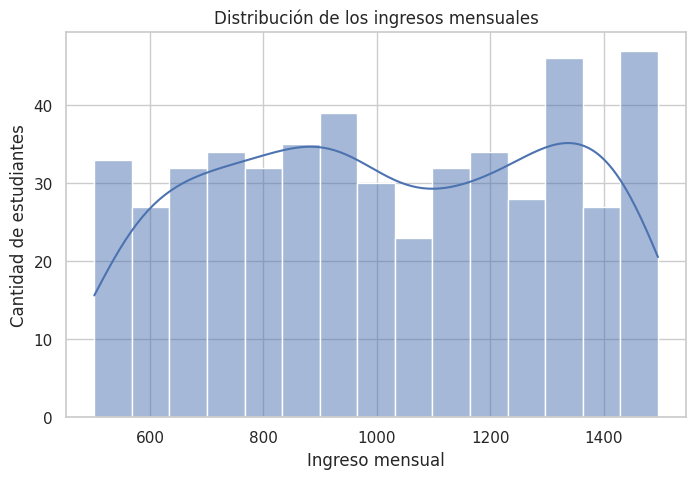

In [14]:
# ==========================================
# DISTRIBUCIÓN DE INGRESOS MENSUALES
# ==========================================

plt.figure(figsize=(8,5))

sns.histplot(
    data=df_limpio,
    x="monthly_income",
    bins=15,
    kde=True
)

plt.title("Distribución de los ingresos mensuales")
plt.xlabel("Ingreso mensual")
plt.ylabel("Cantidad de estudiantes")

plt.show()

Comparación de gastos por categoría

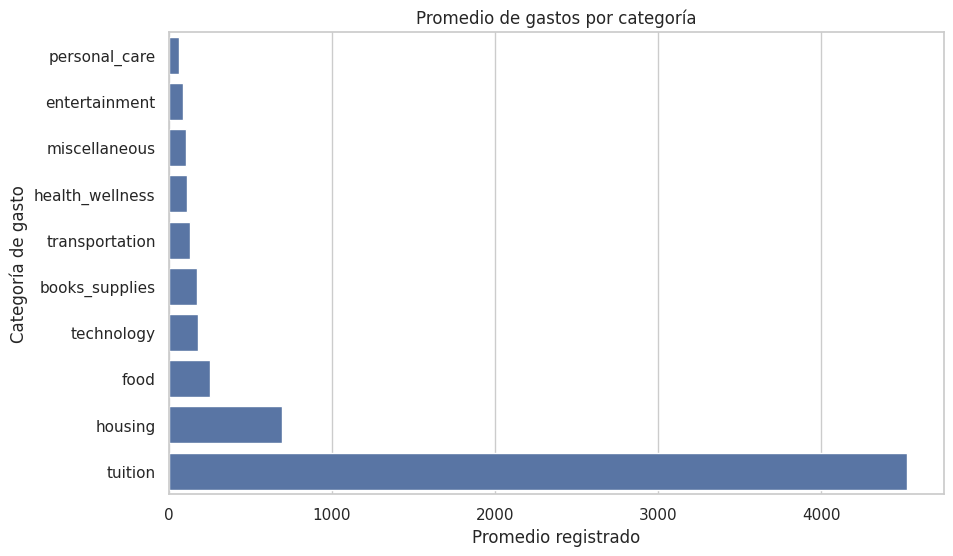

In [15]:
# ==========================================
# COMPARACIÓN DE GASTOS POR CATEGORÍA
# ==========================================

columnas_gastos = [
    "tuition",
    "housing",
    "food",
    "transportation",
    "books_supplies",
    "entertainment",
    "personal_care",
    "technology",
    "health_wellness",
    "miscellaneous"
]

# Calculamos el promedio de cada categoría
promedio_gastos = df_limpio[columnas_gastos].mean().sort_values()

# Creamos el gráfico
plt.figure(figsize=(10,6))

sns.barplot(
    x=promedio_gastos.values,
    y=promedio_gastos.index
)

plt.title("Promedio de gastos por categoría")
plt.xlabel("Promedio registrado")
plt.ylabel("Categoría de gasto")

plt.show()

### Interpretación: promedio de gastos por categoría

Al comparar los promedios de las distintas categorías de gastos, se observa que la matrícula universitaria (tuition) presenta el valor promedio más elevado dentro de la muestra analizada.

Este resultado permite identificar a la educación como una categoría de gasto relevante en la economía de los estudiantes universitarios. Sin embargo, es importante considerar que se deben verificar los períodos de referencia de los importes antes de realizar comparaciones definitivas.

Ingreso promedio según año de cursada

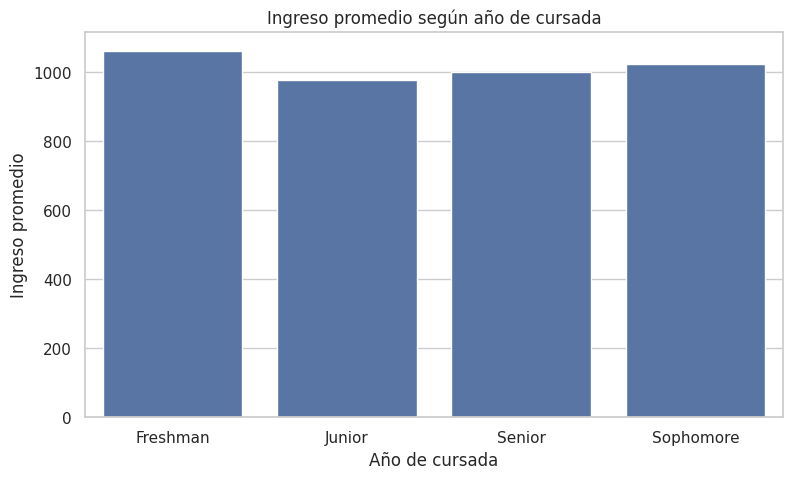

In [16]:
# ==========================================
# INGRESO PROMEDIO SEGÚN AÑO DE CURSADA
# ==========================================

plt.figure(figsize=(9,5))

sns.barplot(
    data=df_limpio,
    x="year_in_school",
    y="monthly_income",
    errorbar=None
)

plt.title("Ingreso promedio según año de cursada")
plt.xlabel("Año de cursada")
plt.ylabel("Ingreso promedio")

plt.show()

### Interpretación: ingresos según año de cursada

Al comparar los ingresos promedio según el año de cursada, se observa que los estudiantes de primer año (Freshman) presentan el promedio más elevado dentro de la muestra.

Este resultado permite identificar diferencias en los ingresos entre los distintos grupos académicos. Sin embargo, no implica necesariamente que el año de cursada sea la causa de estas diferencias.

Ingreso promedio según género

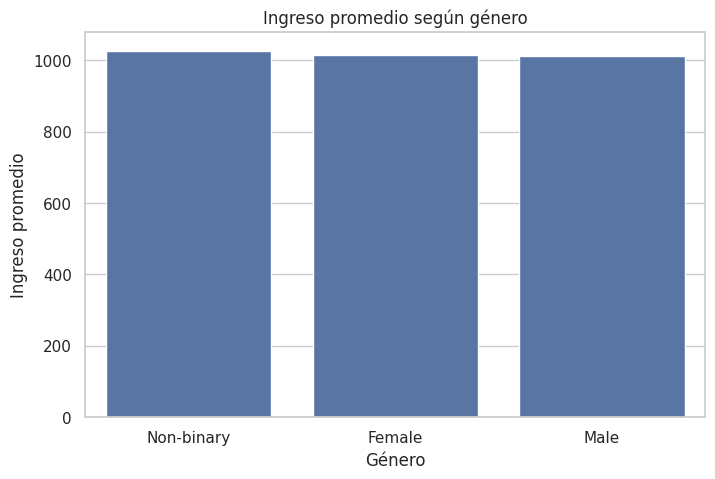

In [19]:
# ==========================================
# INGRESO PROMEDIO SEGÚN GÉNERO
# ==========================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=df_limpio,
    x="gender",
    y="monthly_income",
    errorbar=None
)

plt.title("Ingreso promedio según género")
plt.xlabel("Género")
plt.ylabel("Ingreso promedio")

plt.show()

### Interpretación: ingresos promedio según género

Al analizar los ingresos promedio según género, se observa que la categoría Non-binary presenta el valor promedio más elevado dentro de la muestra.

Este resultado permite identificar diferencias entre las categorías analizadas. Sin embargo, no implica que el género sea la causa de estas diferencias ni permite generalizar los resultados a toda la población universitaria.

Exportación del dataset limpio

In [20]:
# ==========================================
# 11. EXPORTACIÓN DEL DATASET LIMPIO
# ==========================================

df_limpio.to_csv(
    "dataset_limpio.csv",
    index=False
)

print("Dataset limpio exportado correctamente.")

Dataset limpio exportado correctamente.


In [21]:
from google.colab import files

files.download("dataset_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Exportación del dataset limpio